<a href="https://colab.research.google.com/github/faisu6339-glitch/RAG/blob/main/RAG(Document_Loading_pdf_%26_Excel).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -U langchain langchain-community langchain-nvidia-ai-endpoints langchain-text-splitters python-dotenv pypdf pandas openpyxl docx2txt unstructured python-docx

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 981.5/981.5 kB 8.0 MB/s  0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 579.8/579.8 kB 9.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 19.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 19.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 24.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 16.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 610.9/610.9 kB 12.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 19.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.8/3.8 MB 21.0 MB/s  0:00:00
  Created wheel for langdetect: filename=langdetect-1.0.9-py3-none-any.whl size=993332 sha256=aa19f437923a30dc8b697c3914e9eccb7f66f838b62025caf98a5660ea5a6d9c
  Stored in directory: /ro

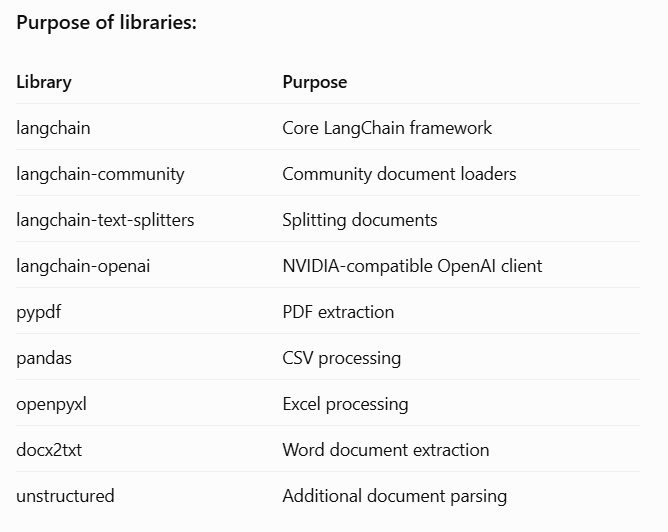

# Phase 1: Document Ingestion and Document Loaders
1. Understanding document ingestion
Document ingestion is the process of collecting data from different sources and preparing it for a RAG application.

For example, imagine you want to create a chatbot that answers questions from your college notes.

You have:
- DBMS.pdf
- Computer_Networks.pdf
- Python_Notes.docx
- Student_Data.csv
- Results.xlsx
Your RAG application needs to read these documents before it can answer questions about them.

Document ingestion pipeline:

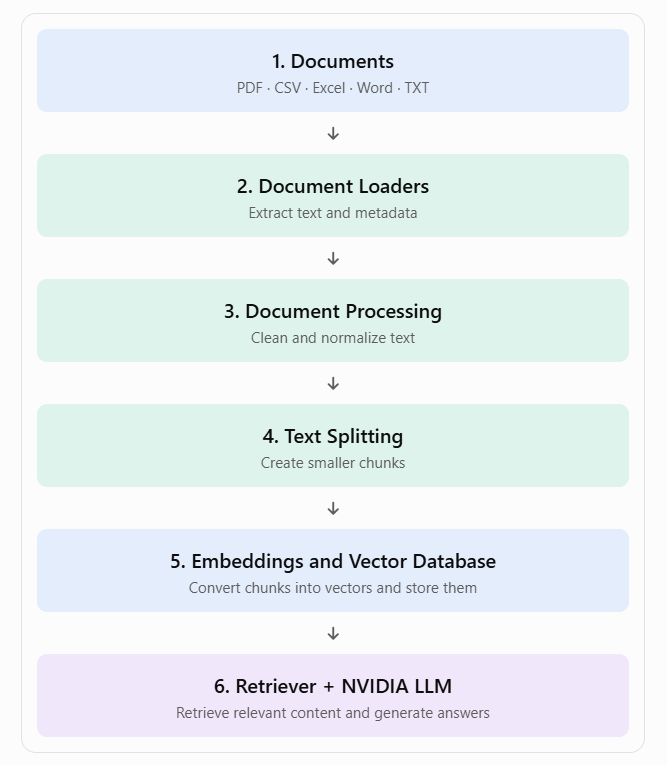

In [1]:
from google.colab import userdata
import os

os.environ["NVIDIA_API_KEY"] = userdata.get("NVIDIA_API_KEY")

print("NVIDIA API Key configured successfully!")

NVIDIA API Key configured successfully!


In [3]:
!pip install -qU langchain-openai

In [4]:
from langchain_openai import ChatOpenAI
import os

llm = ChatOpenAI(
    model="nvidia/nemotron-3.5-lightning-30b-a3b",
    base_url="https://integrate.api.nvidia.com/v1",
    api_key=os.environ["NVIDIA_API_KEY"],
    temperature=0.3
)

response = llm.invoke(
    "Explain what Retrieval Augmented Generation is in 3 lines."
)

print(response.content)

Retrieval Augmented Generation (RAG) combines a retriever and a generator to enhance LLM responses. It first fetches relevant external information from a knowledge base, then uses that context to inform the model's output. This reduces hallucinations and enables access to up-to-date or domain-specific data without retraining.


# . Document Loaders in LangChain
A Document Loader is a component that reads data from a file or source and converts it into LangChain's standard Document format.

A LangChain Document generally contains two important attributes:

In [6]:
from langchain_core.documents import Document
Document(
    page_content="Your extracted text",
    metadata={"source": "DBMS.pdf"}
)

Document(metadata={'source': 'DBMS.pdf'}, page_content='Your extracted text')

In [7]:
from langchain_core.documents import Document

doc = Document(
    page_content="RAG stands for Retrieval Augmented Generation.",
    metadata={
        "source": "rag_notes.txt",
        "subject": "Generative AI"
    }
)

print("Content:", doc.page_content)
print("Metadata:", doc.metadata)

Content: RAG stands for Retrieval Augmented Generation.
Metadata: {'source': 'rag_notes.txt', 'subject': 'Generative AI'}


# Program 2: Create a sample text document and load it
First, create a sample file.

In [8]:
content = """
Retrieval Augmented Generation is known as RAG.

RAG combines information retrieval with language models.

Document ingestion is the first stage of a RAG pipeline.

Documents are converted into smaller chunks.

Embeddings represent text as numerical vectors.

A vector database stores embeddings for similarity search.
"""

with open("rag_notes.txt", "w") as file:
    file.write(content)

In [9]:
from langchain_community.document_loaders import TextLoader

loader = TextLoader("rag_notes.txt", encoding="utf-8")

documents = loader.load()

for doc in documents:
    print(doc.page_content)
    print(doc.metadata)


Retrieval Augmented Generation is known as RAG.

RAG combines information retrieval with language models.

Document ingestion is the first stage of a RAG pipeline.

Documents are converted into smaller chunks.

Embeddings represent text as numerical vectors.

A vector database stores embeddings for similarity search.

{'source': 'rag_notes.txt'}


/tmp/ipykernel_2128/4183482920.py:1: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import TextLoader


# What happens here?
1. TextLoader reads the text file.
2. load() extracts its content.
3. LangChain creates a Document object.
4. The content and metadata become available.

# PDF Loading
PDF loading is important in RAG because many real-world knowledge bases contain research papers, books, reports and academic notes.

We'll use PyPDFLoader.

In [10]:
from google.colab import files

uploaded = files.upload()

pdf_path = next(iter(uploaded))

print("Uploaded PDF:", pdf_path)

Saving GOPLU EXPENSES-1.pdf to GOPLU EXPENSES-1 (1).pdf
Uploaded PDF: GOPLU EXPENSES-1 (1).pdf


# Program 3: Load PDF using PyPDFLoader

In [11]:
from langchain_community.document_loaders import PyPDFLoader

loader = PyPDFLoader(pdf_path)

documents = loader.load()

print("Total pages:", len(documents))

for doc in documents:
    print("Content:")
    print(doc.page_content[:500])

    print("Metadata:")
    print(doc.metadata)

    print("-" * 50)

Total pages: 2
Content:
DATE PARTICULARS AMOUNT
06-05-2026 Cement 10 Bag 3650
06-05-2026 Balu 1 Tractor 4800
06-05-2026 Electric 1000
07-05-2026 Neev Gaddha 1500
08-05-2026 Mistri 1400
08-05-2026 Tub 130
09-05-2026 Material 4700
09-05-2026 Mistri 2 2800
09-05-2026 Exps Chai 200
10-05-2026 Mistri 2000
11-05-2026 Cement+BALU+MAJDURI 8450
11-05-2026 Mistri 2000
12-May Mistri 2000
16-05-2026 Material 3000
16-05-2026 MAJDURI 1400
17-May MAJDURI 1400
19-05-2026 PLUMBER SAMAN 8500
19-05-2026 PLUMBER MAJDURI CHOTU 600
19-05-20
Metadata:
{'producer': 'Microsoft® Excel® 2016', 'creator': 'Microsoft® Excel® 2016', 'creationdate': '2026-06-25T09:03:12+05:30', 'author': 'Md Faisal Sheikh', 'moddate': '2026-06-25T09:03:12+05:30', 'source': 'GOPLU EXPENSES-1 (1).pdf', 'total_pages': 2, 'page': 0, 'page_label': '1'}
--------------------------------------------------
Content:
12-06-2026 MAJDURI 1500
13-06-2026 MAJDURI 1400
14-06-2026 MAJDURI 2000
23-06-2026 MAJDURI 1500
23-06-2026 DOOR 5000
24-06-2026 

# Important concepts:
- PyPDFLoader: Loads PDF documents.
- load(): Loads all pages.
- page_content: Extracted page text.
- metadata: Usually contains source and page number.

# Program 4: Extract a particular PDF page

In [12]:
from langchain_community.document_loaders import PyPDFLoader

loader = PyPDFLoader(pdf_path)

documents = loader.load()

page_number = 0

print(documents[page_number].page_content)

DATE PARTICULARS AMOUNT
06-05-2026 Cement 10 Bag 3650
06-05-2026 Balu 1 Tractor 4800
06-05-2026 Electric 1000
07-05-2026 Neev Gaddha 1500
08-05-2026 Mistri 1400
08-05-2026 Tub 130
09-05-2026 Material 4700
09-05-2026 Mistri 2 2800
09-05-2026 Exps Chai 200
10-05-2026 Mistri 2000
11-05-2026 Cement+BALU+MAJDURI 8450
11-05-2026 Mistri 2000
12-May Mistri 2000
16-05-2026 Material 3000
16-05-2026 MAJDURI 1400
17-May MAJDURI 1400
19-05-2026 PLUMBER SAMAN 8500
19-05-2026 PLUMBER MAJDURI CHOTU 600
19-05-2026 PLUMBER MAJDURI CHOTU 500
20-05-2026 MAJDURI 2000
21-05-2026 CEMENT + MAJDURI 5650
22-05-2026 CHAR+CHARRI 3200
23-05-2026 CHALNI 200
23-05-2026 MAJDURI 1500
24-05-2026 PLUMBER SAMAN 2500
24-05-2026 CHOTU PLUMBER 500
25-05-2026 PLUMBER WALA 1000
25-05-2026 MAJDURI MISTIRI 1400
26-05-2026 PLUMBER SUPPLY MAJDURI 3000
26-05-2026 PLUMBER SAMAN 1365
27-05-2026 1 TRUCTOR BALU 4000
27-05-2026 BALU MAJDURI 800
28-05-2026 PLUMBER SAMAN 500
28-05-2026 PLUMBER CONNECTION 2500
28-05-2026 PLUMBER CHOTU 200

# Program 5: Load PDF page by page and count words

In [13]:
from langchain_community.document_loaders import PyPDFLoader

loader = PyPDFLoader(pdf_path)

documents = loader.load()

for i, doc in enumerate(documents):

    words = doc.page_content.split()

    print("Page:", i + 1)
    print("Word Count:", len(words))
    print("Content:", doc.page_content[:200])
    print("-" * 40)

Page: 1
Word Count: 169
Content: DATE PARTICULARS AMOUNT
06-05-2026 Cement 10 Bag 3650
06-05-2026 Balu 1 Tractor 4800
06-05-2026 Electric 1000
07-05-2026 Neev Gaddha 1500
08-05-2026 Mistri 1400
08-05-2026 Tub 130
09-05-2026 Material 
----------------------------------------
Page: 2
Word Count: 31
Content: 12-06-2026 MAJDURI 1500
13-06-2026 MAJDURI 1400
14-06-2026 MAJDURI 2000
23-06-2026 MAJDURI 1500
23-06-2026 DOOR 5000
24-06-2026 MAJDURI 1500
24-06-2026 CEMENT 340
24-06-2026 CHAI 100
24-06-2026 AMAN E
----------------------------------------


# Program 6: Load multiple PDF files from a folder

In [14]:
import os

from langchain_community.document_loaders import PyPDFLoader

folder_path = "/content/documents"

all_documents = []

for filename in os.listdir(folder_path):

    if filename.endswith(".pdf"):

        file_path = os.path.join(folder_path, filename)

        loader = PyPDFLoader(file_path)

        docs = loader.load()

        all_documents.extend(docs)

print("Total PDF pages loaded:", len(all_documents))

for doc in all_documents:
    print(doc.metadata)

FileNotFoundError: [Errno 2] No such file or directory: '/content/documents'

# Program 1: Create a CSV file

In [15]:
import pandas as pd

data = {
    "Name": ["Rahul", "Aman", "Priya"],
    "Subject": ["Python", "DBMS", "Networks"],
    "Marks": [85, 90, 88]
}

df = pd.DataFrame(data)

df.to_csv("students.csv", index=False)

print(df)

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


    Name   Subject  Marks
0  Rahul    Python     85
1   Aman      DBMS     90
2  Priya  Networks     88


# Program 2: Load CSV using CSVLoader

In [16]:
from langchain_community.document_loaders import CSVLoader

loader = CSVLoader(file_path="students.csv")

documents = loader.load()

for doc in documents:

    print("Content:")
    print(doc.page_content)

    print("Metadata:")
    print(doc.metadata)

    print("-" * 40)

Content:
Name: Rahul
Subject: Python
Marks: 85
Metadata:
{'source': 'students.csv', 'row': 0}
----------------------------------------
Content:
Name: Aman
Subject: DBMS
Marks: 90
Metadata:
{'source': 'students.csv', 'row': 1}
----------------------------------------
Content:
Name: Priya
Subject: Networks
Marks: 88
Metadata:
{'source': 'students.csv', 'row': 2}
----------------------------------------


# Program 3: Load CSV using a specific column

In [17]:
from langchain_community.document_loaders import CSVLoader

loader = CSVLoader(
    file_path="students.csv",
    source_column="Name"
)

documents = loader.load()

for doc in documents:

    print("Content:", doc.page_content)
    print("Source:", doc.metadata["source"])

Content: Name: Rahul
Subject: Python
Marks: 85
Source: Rahul
Content: Name: Aman
Subject: DBMS
Marks: 90
Source: Aman
Content: Name: Priya
Subject: Networks
Marks: 88
Source: Priya


# Program 4: Load CSV using Pandas and convert it into Documents

In [18]:
import pandas as pd

from langchain_core.documents import Document

df = pd.read_csv("students.csv")

documents = []

for index, row in df.iterrows():

    content = f"""
    Student Name: {row['Name']}
    Subject: {row['Subject']}
    Marks: {row['Marks']}
    """

    doc = Document(
        page_content=content,
        metadata={
            "row": index,
            "source": "students.csv"
        }
    )

    documents.append(doc)

for doc in documents:
    print(doc.page_content)
    print(doc.metadata)


    Student Name: Rahul
    Subject: Python
    Marks: 85
    
{'row': 0, 'source': 'students.csv'}

    Student Name: Aman
    Subject: DBMS
    Marks: 90
    
{'row': 1, 'source': 'students.csv'}

    Student Name: Priya
    Subject: Networks
    Marks: 88
    
{'row': 2, 'source': 'students.csv'}


# Program 5: Create an Excel file

In [19]:
import pandas as pd

students = pd.DataFrame({
    "Name": ["Rahul", "Aman", "Priya"],
    "Course": ["BCA", "MCA", "BCA"],
    "Marks": [85, 90, 88]
})

teachers = pd.DataFrame({
    "Name": ["Mr. Sharma", "Ms. Gupta"],
    "Subject": ["Python", "DBMS"]
})

with pd.ExcelWriter("college.xlsx") as writer:

    students.to_excel(
        writer,
        sheet_name="Students",
        index=False
    )

    teachers.to_excel(
        writer,
        sheet_name="Teachers",
        index=False
    )

print("Excel file created!")

Excel file created!


# Program 6: Load Excel using Pandas

In [20]:
import pandas as pd

excel_file = pd.ExcelFile("college.xlsx")

print("Available sheets:", excel_file.sheet_names)

for sheet in excel_file.sheet_names:

    df = pd.read_excel(
        "college.xlsx",
        sheet_name=sheet
    )

    print("\nSheet:", sheet)
    print(df)

Available sheets: ['Students', 'Teachers']

Sheet: Students
    Name Course  Marks
0  Rahul    BCA     85
1   Aman    MCA     90
2  Priya    BCA     88

Sheet: Teachers
         Name Subject
0  Mr. Sharma  Python
1   Ms. Gupta    DBMS


# Program 7: Convert Excel rows into LangChain Documents

In [21]:
import pandas as pd

from langchain_core.documents import Document

excel_file = pd.ExcelFile("college.xlsx")

documents = []

for sheet in excel_file.sheet_names:

    df = pd.read_excel(
        "college.xlsx",
        sheet_name=sheet
    )

    for index, row in df.iterrows():

        content = ", ".join(
            f"{column}: {value}"
            for column, value in row.items()
        )

        doc = Document(
            page_content=content,
            metadata={
                "source": "college.xlsx",
                "sheet": sheet,
                "row": index
            }
        )

        documents.append(doc)

print("Total documents:", len(documents))

for doc in documents:

    print("\nContent:", doc.page_content)
    print("Metadata:", doc.metadata)

Total documents: 5

Content: Name: Rahul, Course: BCA, Marks: 85
Metadata: {'source': 'college.xlsx', 'sheet': 'Students', 'row': 0}

Content: Name: Aman, Course: MCA, Marks: 90
Metadata: {'source': 'college.xlsx', 'sheet': 'Students', 'row': 1}

Content: Name: Priya, Course: BCA, Marks: 88
Metadata: {'source': 'college.xlsx', 'sheet': 'Students', 'row': 2}

Content: Name: Mr. Sharma, Subject: Python
Metadata: {'source': 'college.xlsx', 'sheet': 'Teachers', 'row': 0}

Content: Name: Ms. Gupta, Subject: DBMS
Metadata: {'source': 'college.xlsx', 'sheet': 'Teachers', 'row': 1}


# Program 8: Upload and load an Excel file

In [22]:
from google.colab import files

uploaded = files.upload()

excel_path = next(iter(uploaded))

import pandas as pd

df = pd.read_excel(excel_path)

print(df.head())

StopIteration: 